In [2]:
from transformers import GPT2LMHeadModel

In [39]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [3]:
model_hf = GPT2LMHeadModel.from_pretrained("gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [4]:
sd_hf = model_hf.state_dict()

In [ ]:
for k, v in sd_hf.items():
    print(k, v.shape)

import matplotlib.pyplot as plt
plt.figure(figsize=(20, 20))
plt.imshow(sd_hf["transformer.wpe.weight"], cmap="grey")

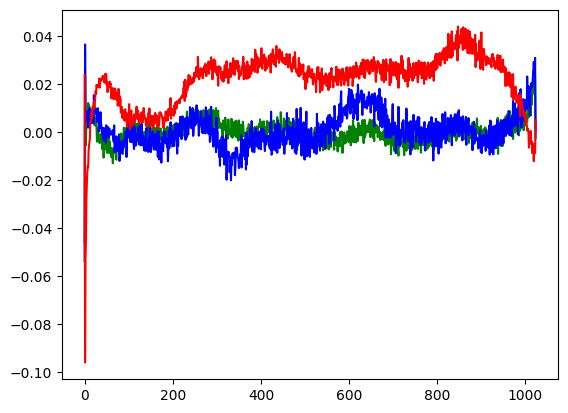

In [7]:
plt.plot(sd_hf["transformer.wpe.weight"][:, 150], color="green")
plt.plot(sd_hf["transformer.wpe.weight"][:, 200], color="blue")
plt.plot(sd_hf["transformer.wpe.weight"][:, 250], color="red")



In [8]:
from transformers import pipeline, set_seed

In [9]:
generator = pipeline("text-generation", model="gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [10]:
x = torch.randn(4, 4, 4)

In [11]:
x.split(2, 2)

(tensor([[[ 0.3902, -1.4599],
          [ 0.1330,  0.0107],
          [-0.2664, -1.8835],
          [-0.4984,  0.2054]],
 
         [[-0.9249, -0.8177],
          [ 0.0346, -1.9045],
          [ 0.5476,  1.5165],
          [-1.7781, -0.9997]],
 
         [[ 0.4642,  0.2697],
          [-0.9187,  0.2491],
          [-0.8430,  0.2649],
          [ 1.2256, -0.4552]],
 
         [[ 0.2201,  1.3764],
          [-0.7092, -1.2876],
          [-0.0277,  0.6806],
          [ 0.6845,  0.7460]]]),
 tensor([[[-1.5529,  1.1525],
          [ 1.6118,  0.2111],
          [-0.9557, -0.7606],
          [-0.0775, -2.1101]],
 
         [[ 0.2357, -0.5087],
          [-0.4180, -0.8054],
          [ 1.1831,  0.8873],
          [ 0.2017,  0.9582]],
 
         [[-0.6485,  0.9126],
          [ 0.5099,  0.2853],
          [ 0.2304,  0.3909],
          [-0.5304, -0.6925]],
 
         [[ 1.3353,  1.2479],
          [ 0.5875, -1.0503],
          [-1.0007,  0.4726],
          [ 1.2151,  1.0394]]]))

In [26]:
a = torch.randint(10, (10, 10, 5, 5)).float()

In [27]:
mask = torch.tril(torch.ones(5, 5))

In [28]:
a = torch.masked_fill(a, mask == 0, float("-inf"))

In [37]:
a.contiguous().shape

torch.Size([10, 10, 5, 5])

In [36]:
a.shape

torch.Size([10, 10, 5, 5])

In [42]:
x = {"a" : 10, "b" : 20, "c" : 30}


TypeError: 'a' is an invalid keyword argument for print()